### LIBRARIES & IMPORT FOR SET UP

In [3]:
# Standard libraries
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import random

In [4]:

# Detectron2 imports
from detectron2 import model_zoo # A collection of pre-traied models hosted by Detectron2 (+100 like Mask R-CNN, Fast R-CNN, RetinaNet,..)
from detectron2.config import get_cfg # Configuration object because Detectron2 use config to control everything like model architecture, 
                                        # training, dataset,...(It's like a panel  of options)

from detectron2.engine import DefaultPredictor #The Dectron2 engine which realize all the complex hidden tasks like prepocesing data,
                                                #forwarding data through the model, postprocessing the outputs,...
from detectron2.utils.visualizer import Visualizer, ColorMode
from detectron2.data import DatasetCatalog, MetadataCatalog

### LOAD DATASET : Get info about my cityscapes dataset that I registered in 01_data_exploration.ipynb

In [6]:
# ============================================
# LOAD DATASET USING SHARED MODULE
# ============================================
# Import our custom dataset loader (professional approach!)

import sys
from pathlib import Path

# Add project root to path so we can import our modules
PROJECT_ROOT = Path.home() / "VS_Code" / "INSEG_PRO"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from data.dataset_loader import setup_dataset

# Setup dataset (automatically detects Cityscapes or falls back to COCO)
dataset_name, dataset_dicts, metadata = setup_dataset(
    use_cityscapes=True,  # Will auto-fallback to COCO if not available
    split="val"
)

print(f"✅ Loaded {len(dataset_dicts)} images from {dataset_name}")
print(f"   Classes: {metadata.thing_classes}")

✅ Loaded 492 images from cityscapes_custom_val
   Classes: ['person', 'rider', 'car', 'truck', 'bus', 'train', 'motorcycle', 'bicycle']


### CONFIGURE MY PRETRAINED R-CNN MODEL

In [7]:
# Create configuration
cfg = get_cfg()

# Load model architecture config
cfg.merge_from_file(
    model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")
)

# Load pretrained weights
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(
    "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
)

# Set device (CPU or GPU)
cfg.MODEL.DEVICE = "cpu"  # Change to "cuda" in Colab

# Set confidence threshold
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5

# Print model info
print("✅ Model configuration:")
print(f"   Architecture: Mask R-CNN")
print(f"   Backbone: ResNet-50 + FPN")
print(f"   Trained on: COCO dataset")
print(f"   Classes: 80 object categories")
print(f"   Confidence threshold: {cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST}")
print(f"   Device: {cfg.MODEL.DEVICE}")

✅ Model configuration:
   Architecture: Mask R-CNN
   Backbone: ResNet-50 + FPN
   Trained on: COCO dataset
   Classes: 80 object categories
   Confidence threshold: 0.5
   Device: cpu


### CREATE THE PREDICTOR, THE INFERENCE ENGINE THAT WILL RUN THE MODEL ON IMAGES

In [8]:
# Create predictor
predictor = DefaultPredictor(cfg)

print("✅ Predictor created and ready")
print(f"   Model loaded into memory")
print(f"   Input format: BGR image (height, width, 3)")
print(f"   Output format: Instances object with boxes, masks, scores")

model_final_f10217.pkl: 178MB [00:45, 3.90MB/s]                              


✅ Predictor created and ready
   Model loaded into memory
   Input format: BGR image (height, width, 3)
   Output format: Instances object with boxes, masks, scores


### TEST ON SINGLE IMAGE

In [9]:
# Select a random image
sample = random.choice(dataset_dicts)
image_path = sample["file_name"]

print(f"Testing on: {Path(image_path).name}")

# Load image
img = cv2.imread(image_path)
print(f"Image shape: {img.shape}")  # (height, width, 3)

# Run inference
print("Running inference...")
outputs = predictor(img)

# Extract predictions
instances = outputs["instances"].to("cpu")
num_detections = len(instances)

print(f"\n✅ Inference complete!")
print(f"   Detected {num_detections} objects")
print(f"   Output keys: {outputs.keys()}")
print(f"   Instance fields: {instances.get_fields().keys()}")

Testing on: munster_000141_000019_leftImg8bit.png
Image shape: (1024, 2048, 3)
Running inference...


/home/rachidjunior/miniconda3/envs/inseg_proj/lib/python3.10/site-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W0204 13:34:17.361000 18973 site-packages/torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.



✅ Inference complete!
   Detected 46 objects
   Output keys: dict_keys(['instances'])
   Instance fields: dict_keys(['pred_boxes', 'scores', 'pred_classes', 'pred_masks'])


### VISUALIZE PREDICTIONS

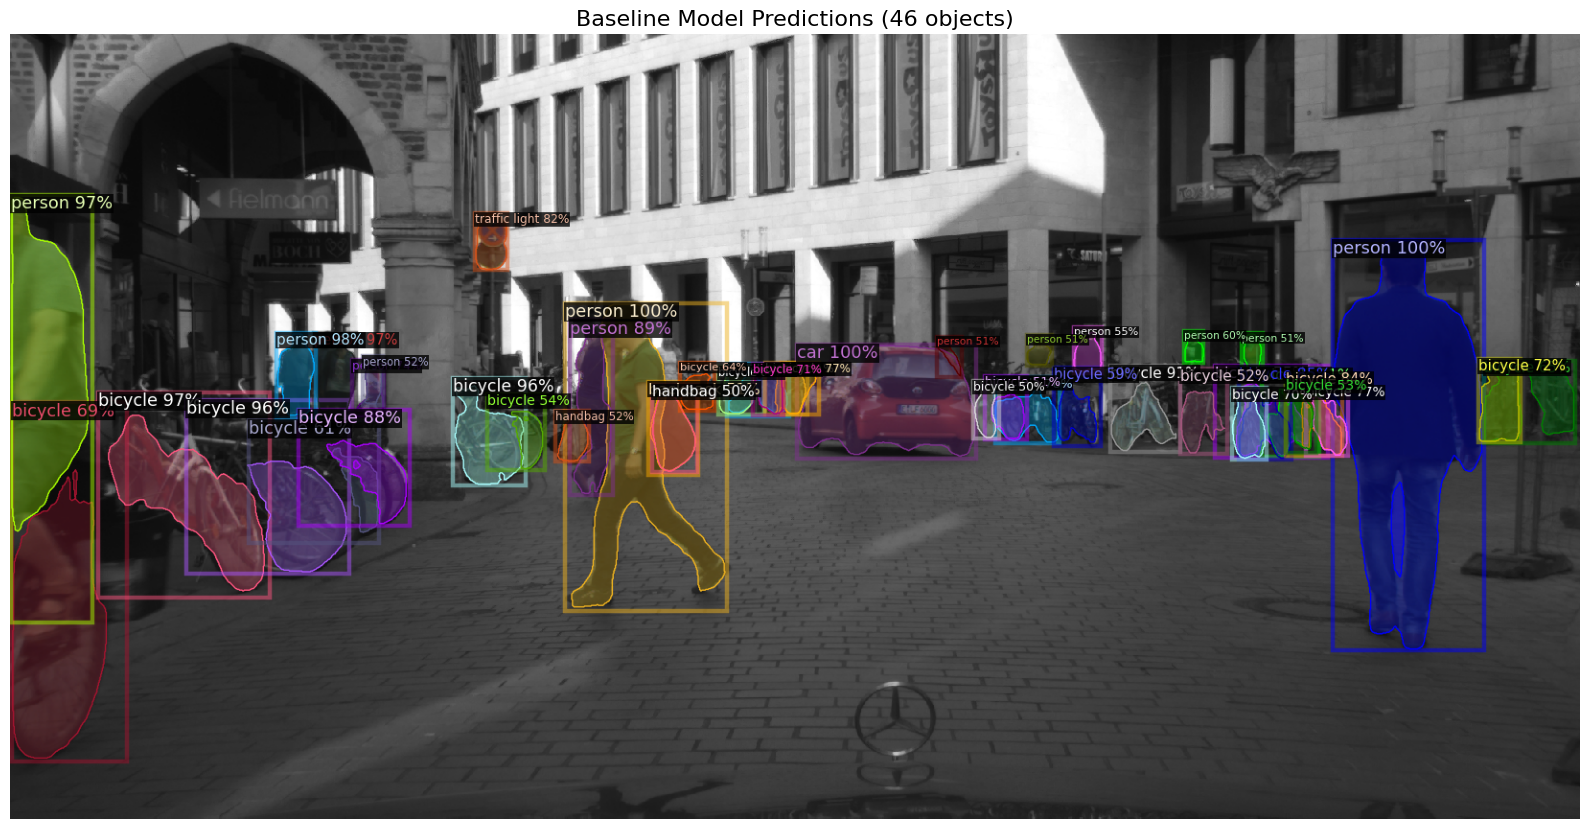

In [10]:
# Create visualizer
v = Visualizer(
    img[:, :, ::-1],  # Convert BGR to RGB
    metadata=MetadataCatalog.get("coco_2017_val"),  # Use COCO metadata (80 classes)
    scale=0.8,
    instance_mode=ColorMode.IMAGE_BW  # Show masks on grayscale background
)

# Draw predictions
out = v.draw_instance_predictions(instances)

# Display
plt.figure(figsize=(16, 10))
plt.imshow(out.get_image())
plt.axis('off')
plt.title(f"Baseline Model Predictions ({num_detections} objects)", fontsize=16)
plt.tight_layout()

# Save
output_dir = Path("../outputs")
output_dir.mkdir(exist_ok=True)
plt.savefig(output_dir / "baseline_prediction.png", dpi=150, bbox_inches='tight')
plt.show()

### ANALYZE PREDICTIS VS GROUND TRUTH 

In [ ]:
# Get ground truth annotations
gt_annotations = sample["annotations"]
num_gt = len(gt_annotations)

print(f"Comparison:")
print(f"  Ground truth objects: {num_gt}")
print(f"  Detected objects: {num_detections}")
print(f"  Difference: {num_detections - num_gt}")

# Count by class
from collections import Counter

# Ground truth class distribution
gt_classes = [ann["category_id"] for ann in gt_annotations]
gt_class_names = [metadata.thing_classes[cid] for cid in gt_classes]
gt_counts = Counter(gt_class_names)

# Prediction class distribution (map COCO classes to Cityscapes)
coco_metadata = MetadataCatalog.get("coco_2017_val")
pred_class_ids = instances.pred_classes.numpy()
pred_class_names = [coco_metadata.thing_classes[cid] for cid in pred_class_ids]
pred_counts = Counter(pred_class_names)

# Compare
print(f"\nClass-wise comparison:\n")
print(f"{'Class':<15} {'Ground Truth':<15} {'Predicted':<15}")
print("-" * 45)

all_classes = set(gt_counts.keys()) | set(pred_counts.keys())
for cls in sorted(all_classes):
    gt_count = gt_counts.get(cls, 0)
    pred_count = pred_counts.get(cls, 0)
    print(f"{cls:<15} {gt_count:<15} {pred_count:<15}")

Comparison:
  Ground truth objects: 43
  Detected objects: 46
  Difference: 3

Class-wise comparison:
Class           Ground Truth    Predicted      
---------------------------------------------
backpack        0               1              
bicycle         22              28             
car             1               1              
handbag         0               2              
person          19              13             
rider           1               0              
traffic light   0               1              
